<a href="https://colab.research.google.com/github/nndna/Neurodata-Machine-Learning---HW1/blob/main/HW1_clean_student_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

# Use the same plot settings for all graphs
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11})

file_path = '/content/106r002p70_spikes.mat'

# Try a local file if we are not using Colab
if not Path(file_path).exists():
    file_path = '106r002p70_spikes.mat'

with h5py.File(file_path, 'r') as f:
    stim_data = np.array(f['stim'])
    spike_refs = f['spikes']
    v1_spikes = np.array(f[spike_refs[0, 0]])
    v2_spikes = np.array(f[spike_refs[1, 0]])

print('V1:', v1_spikes.shape)
print('V2:', v2_spikes.shape)
print('Stimuli:', stim_data.shape)

V1: (3200, 1280, 88)
V2: (3200, 1280, 24)
Stimuli: (1, 3200)


## 1. From raw spikes to a tuning curve (15 points)

Each trial lasts 1280 ms. We add up the spikes for each trial, group trials by orientation, and calculate the mean response for each neuron.


In [27]:
# The second axis is time, so we add the 1280 time bins
spike_counts = np.sum(v1_spikes, axis=1)

# Get one stimulus code per trial
stim = stim_data.flatten()
orientations, trial_counts = np.unique(stim, return_counts=True)

print('Spike count shape:', spike_counts.shape)
print('Stimulus codes:', orientations)
print('Trials for each code:', trial_counts)
print('Number of V1 neurons:', v1_spikes.shape[2])

Spike count shape: (3200, 88)
Stimulus codes: [1. 2. 3. 4. 5. 6. 7. 8.]
Trials for each code: [400 400 400 400 400 400 400 400]
Number of V1 neurons: 88


In [28]:
# One row for each neuron and one column for each orientation
mean_responses = np.zeros((v1_spikes.shape[2], len(orientations)))

for neuron in range(v1_spikes.shape[2]):
    for i, ori in enumerate(orientations):
        # Only take trials that used this orientation
        trials = spike_counts[stim == ori, neuron]
        mean_responses[neuron, i] = np.mean(trials)

print('Mean responses:', mean_responses.shape)

Mean responses: (88, 8)


In [29]:
# Mean response for each neuron at each orientation
# Final shape: (88 neurons, 8 orientations)
mean_responses = np.zeros((88, len(orientations)))

for neuron in range(88):
    for i, ori in enumerate(orientations):
        trials = spike_counts[stim == ori, neuron]
        mean_responses[neuron, i] = np.mean(trials)

print("Shape of mean_responses:", mean_responses.shape)

# Average mean response across all neurons
mean_across_neurons = np.mean(mean_responses, axis=0)

print("Average response across all neurons:")
for i, ori in enumerate(orientations):
    print(f"Orientation {int(ori)}: {mean_across_neurons[i]:.3f} spikes/trial")

Shape of mean_responses: (88, 8)
Average response across all neurons:
Orientation 1: 17.396 spikes/trial
Orientation 2: 15.358 spikes/trial
Orientation 3: 14.825 spikes/trial
Orientation 4: 13.999 spikes/trial
Orientation 5: 13.820 spikes/trial
Orientation 6: 13.371 spikes/trial
Orientation 7: 13.368 spikes/trial
Orientation 8: 15.665 spikes/trial


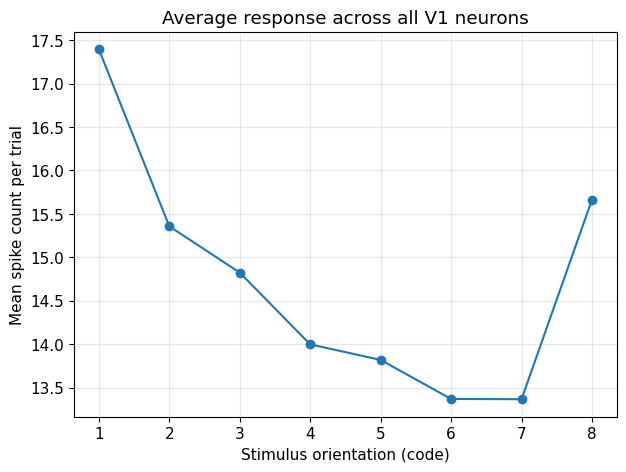

In [30]:
plt.figure(figsize=(7, 5))
plt.plot(orientations, mean_across_neurons, marker='o')
plt.xlabel('Stimulus orientation (code)')
plt.ylabel('Mean spike count per trial')
plt.title('Average response across all V1 neurons')
plt.xticks(orientations)
plt.grid(alpha=0.3)
plt.show()

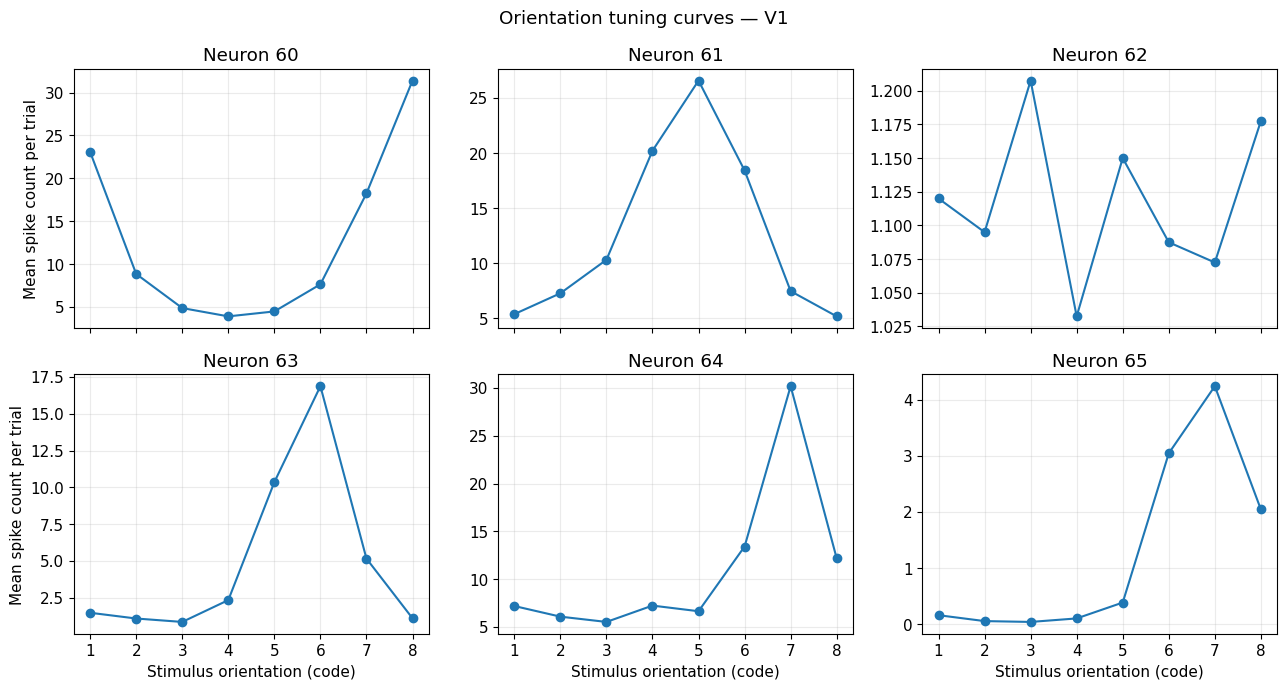

In [31]:
# Look at a few neurons, including our selected neuron 61
selected_neurons = [60, 61, 62, 63, 64, 65]

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)

for ax, neuron in zip(axes.flat, selected_neurons):
    ax.plot(orientations, mean_responses[neuron], 'o-', color='tab:blue')
    ax.set_title(f'Neuron {neuron}')
    ax.set_xticks(orientations)
    ax.grid(alpha=0.25)

for ax in axes[-1]:
    ax.set_xlabel('Stimulus orientation (code)')
for ax in axes[:, 0]:
    ax.set_ylabel('Mean spike count per trial')

fig.suptitle('Orientation tuning curves — V1')
plt.tight_layout()
plt.show()

We chose neuron 61 because its mean response has a clear peak around stimulus code 5.

## 2. Polynomial regression

For regression, we use firing rate in spikes/s. The stimulus lasts 1.28 seconds, so we divide the mean spike counts by 1.28. We fit degrees 1, 3, 4, and 7.


In [32]:
# Convert the mean response to spikes per second
mean_rates = mean_responses / 1.28

neuron_idx = 61
x = orientations
y = mean_rates[neuron_idx]

In [33]:
# Fit each polynomial and calculate its MSE
polynomial_degrees = [1, 3, 4, 7]
polynomial_fits = {}
polynomial_mse = {}

for degree in polynomial_degrees:
    coefficients = np.polyfit(x, y, degree)
    predictions = np.polyval(coefficients, x)
    mse = np.mean((y - predictions) ** 2)
    polynomial_fits[degree] = coefficients
    polynomial_mse[degree] = mse
    print(f'Degree {degree} MSE: {mse:.4f}')

Degree 1 MSE: 34.1891
Degree 3 MSE: 8.1273
Degree 4 MSE: 2.2963
Degree 7 MSE: 0.0000


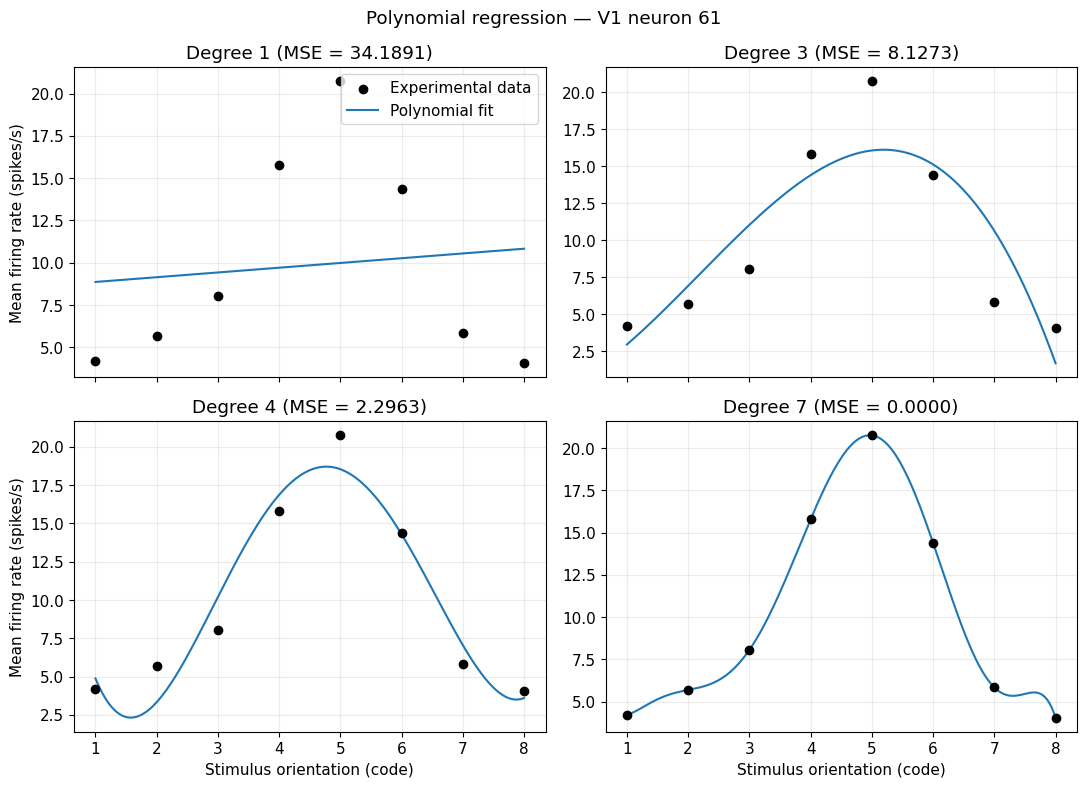

In [34]:
# Plot the four polynomial fits
x_smooth = np.linspace(x.min(), x.max(), 200)
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)

for ax, degree in zip(axes.flat, polynomial_degrees):
    y_smooth = np.polyval(polynomial_fits[degree], x_smooth)
    ax.scatter(x, y, color='black', label='Experimental data', zorder=3)
    ax.plot(x_smooth, y_smooth, color='tab:blue', label='Polynomial fit')
    ax.set_title(f'Degree {degree} (MSE = {polynomial_mse[degree]:.4f})')
    ax.set_xticks(x)
    ax.grid(alpha=0.25)

for ax in axes[-1]:
    ax.set_xlabel('Stimulus orientation (code)')
for ax in axes[:, 0]:
    ax.set_ylabel('Mean firing rate (spikes/s)')

axes[0, 0].legend()
fig.suptitle('Polynomial regression — V1 neuron 61')
plt.tight_layout()
plt.show()

The degree-7 polynomial fits all eight measured mean responses very closely. This does not necessarily mean it will predict new responses well.

## 3. Nonlinear regression

We fit a Gaussian curve to the same neuron. The parameters describe baseline response, amplitude, preferred orientation, and tuning width.


In [35]:
def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(-((theta - mu) ** 2) / (2 * sigma ** 2))

# Start with values suggested by the data
B0 = np.min(y)
A0 = np.max(y) - B0
mu0 = x[np.argmax(y)]
sigma0 = 1.0

params, covariance = curve_fit(
    gaussian, x, y,
    p0=[B0, A0, mu0, sigma0],
    bounds=([0, 0, 1, 0.01], [np.inf, np.inf, 8, np.inf])
)

B, A, mu, sigma = params
y_pred_gaussian = gaussian(x, B, A, mu, sigma)
mse_gaussian = np.mean((y - y_pred_gaussian) ** 2)

print(f'Baseline (B): {B:.3f} spikes/s')
print(f'Amplitude (A): {A:.3f} spikes/s')
print(f'Preferred orientation (mu): {mu:.3f} codes')
print(f'Tuning width (sigma): {sigma:.3f} code units')
print(f'Gaussian MSE: {mse_gaussian:.4f}')

Baseline (B): 4.284 spikes/s
Amplitude (A): 16.591 spikes/s
Preferred orientation (mu): 4.887 codes
Tuning width (sigma): 1.070 code units
Gaussian MSE: 0.2706


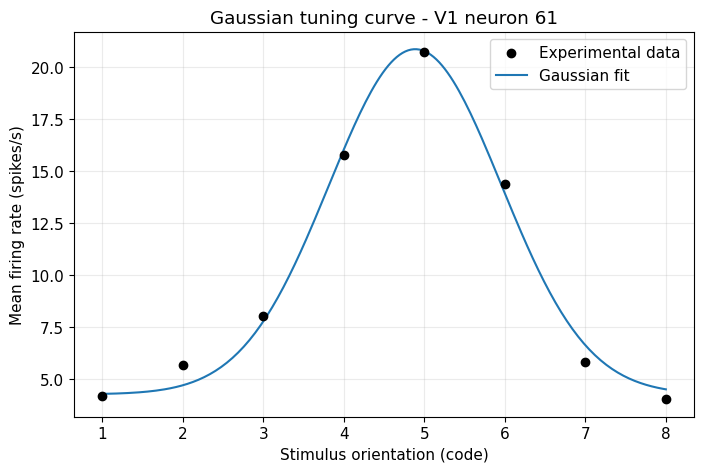

In [36]:
# Show the data and our Gaussian curve
plt.figure()
plt.scatter(x, y, color='black', label='Experimental data', zorder=3)
plt.plot(x_smooth, gaussian(x_smooth, B, A, mu, sigma),
         color='tab:blue', label='Gaussian fit')
plt.title('Gaussian tuning curve - V1 neuron 61')
plt.xlabel('Stimulus orientation (code)')
plt.ylabel('Mean firing rate (spikes/s)')
plt.xticks(x)
plt.grid(alpha=0.25)
plt.legend()
plt.show()

We also try the Gaussian model on neuron 0. Its tuning curve is not as clearly bell-shaped as the one for neuron 61.


In [37]:
# Repeat the Gaussian fit for neuron 0
other_neuron = 0
y0 = mean_rates[other_neuron]

B0 = np.min(y0)
A0 = np.max(y0) - B0
mu0 = x[np.argmax(y0)]
sigma0 = 1.0

params0, covariance0 = curve_fit(
    gaussian, x, y0,
    p0=[B0, A0, mu0, sigma0],
    bounds=([0, 0, 1, 0.01], [np.inf, np.inf, 8, np.inf])
)

B_0, A_0, mu_0, sigma_0 = params0
mse_gaussian0 = np.mean((y0 - gaussian(x, *params0)) ** 2)

print(f'Baseline (B): {B_0:.3f} spikes/s')
print(f'Amplitude (A): {A_0:.3f} spikes/s')
print(f'Preferred orientation (mu): {mu_0:.3f} codes')
print(f'Tuning width (sigma): {sigma_0:.3f} code units')
print(f'Gaussian MSE: {mse_gaussian0:.4f}')

Baseline (B): 11.550 spikes/s
Amplitude (A): 10.028 spikes/s
Preferred orientation (mu): 1.422 codes
Tuning width (sigma): 0.269 code units
Gaussian MSE: 0.7540


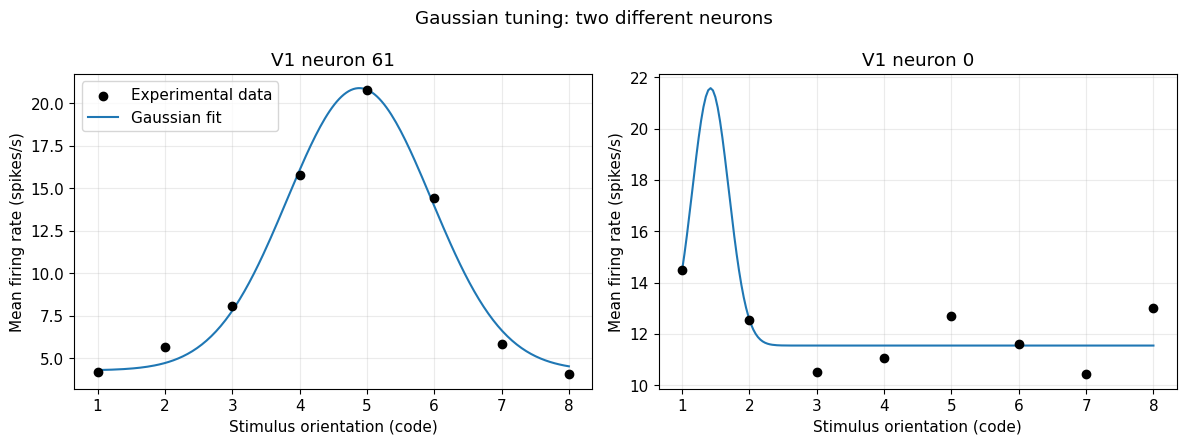

In [38]:
# Plot both Gaussian fits
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for ax, neuron, responses, fit_params in [
    (axes[0], 61, y, params),
    (axes[1], 0, y0, params0)
]:
    ax.scatter(x, responses, color='black', label='Experimental data', zorder=3)
    ax.plot(x_smooth, gaussian(x_smooth, *fit_params),
            color='tab:blue', label='Gaussian fit')
    ax.set_title(f'V1 neuron {neuron}')
    ax.set_xlabel('Stimulus orientation (code)')
    ax.set_xticks(x)
    ax.grid(alpha=0.25)

axes[0].set_ylabel('Mean firing rate (spikes/s)')
axes[1].set_ylabel('Mean firing rate (spikes/s)')
axes[0].legend()
fig.suptitle('Gaussian tuning: two different neurons')
plt.tight_layout()
plt.show()

In [39]:
# Compare the model parameters
print('Parameter             Neuron 61    Neuron 0')
print(f'Baseline (spikes/s)   {B:9.3f}   {B_0:9.3f}')
print(f'Amplitude (spikes/s)  {A:9.3f}   {A_0:9.3f}')
print(f'Mu (code)             {mu:9.3f}   {mu_0:9.3f}')
print(f'Sigma (code units)    {sigma:9.3f}   {sigma_0:9.3f}')
print(f'MSE                    {mse_gaussian:8.4f}    {mse_gaussian0:8.4f}')

Parameter             Neuron 61    Neuron 0
Baseline (spikes/s)       4.284      11.550
Amplitude (spikes/s)     16.591      10.028
Mu (code)                 4.887       1.422
Sigma (code units)        1.070       0.269
MSE                      0.2706      0.7540


The Gaussian fit for neuron 0 has a narrow peak between measured orientations. This makes the small value of sigma harder to interpret.


In [40]:
# Compare the models that we have fitted to neuron 61
for degree in polynomial_degrees:
    print(f'Polynomial degree {degree}: {polynomial_mse[degree]:.4f}')
print(f'Gaussian: {mse_gaussian:.4f}')

Polynomial degree 1: 34.1891
Polynomial degree 3: 8.1273
Polynomial degree 4: 2.2963
Polynomial degree 7: 0.0000
Gaussian: 0.2706


## 4. A problem with orientation (20 points)

Orientations of 0 and 180 degrees are equivalent. We convert the stimulus codes into angles and use the von Mises model to account for this.


In [41]:
# Convert stimulus codes into angles in degrees
angles_deg = (orientations - 1) * 22.5

# Convert degrees into radians
angles_rad = np.deg2rad(angles_deg)

# Mean firing rates for our selected neuron
y = mean_rates[61]

print(angles_deg)
print(angles_rad)
print(y)

[  0.   22.5  45.   67.5  90.  112.5 135.  157.5]
[0.         0.39269908 0.78539816 1.17809725 1.57079633 1.96349541
 2.35619449 2.74889357]
[ 4.20898438  5.6875      8.05859375 15.78710938 20.75390625 14.38867188
  5.83789062  4.05078125]


In [42]:
def von_mises(theta, B, A, mu, kappa):
    return B + A * np.exp(kappa * np.cos(2 * (theta - mu)))

In [43]:
# Initial guesses
B0 = np.min(y)
kappa0 = 1.0
mu0 = angles_rad[np.argmax(y)]
A0 = (np.max(y) - B0) / np.exp(kappa0)

# Fit the model
params_vm, covariance_vm = curve_fit(
    von_mises,
    angles_rad,
    y,
    p0=[B0, A0, mu0, kappa0],
    bounds=(
        [0, 0, 0, 0],
        [np.inf, np.inf, np.pi, 20]
    ),
    maxfev=10000
)

B_vm, A_vm, mu_vm, kappa_vm = params_vm

print(f'Baseline (B): {B_vm:.3f}')
print(f'Amplitude (A): {A_vm:.3f}')
print(f'Preferred orientation (mu): {np.rad2deg(mu_vm):.3f} degrees')
print(f'Concentration (kappa): {kappa_vm:.3f}')

Baseline (B): 3.097
Amplitude (A): 4.249
Preferred orientation (mu): 87.420 degrees
Concentration (kappa): 1.439


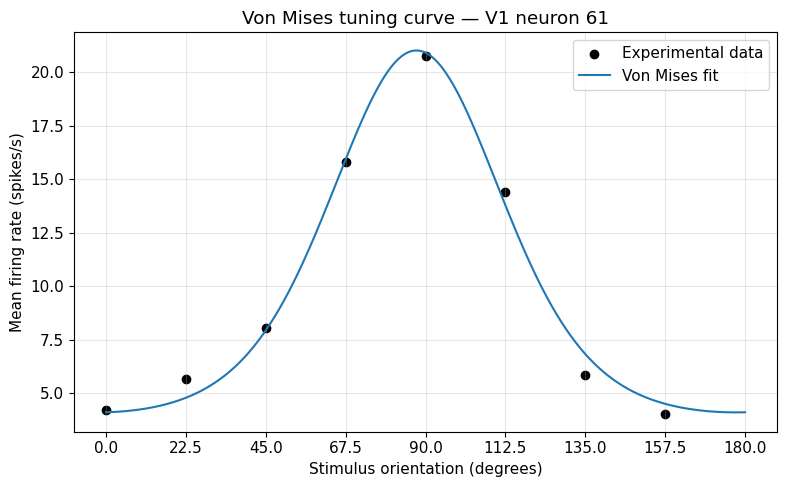

In [44]:
# Smooth angles for the fitted curve
x_smooth = np.linspace(0, 180, 300)
x_smooth_rad = np.deg2rad(x_smooth)

# Predicted response
y_smooth = von_mises(
    x_smooth_rad, B_vm, A_vm, mu_vm, kappa_vm
)

plt.figure(figsize=(8, 5))

plt.scatter(angles_deg, y, color='black', label='Experimental data')
plt.plot(x_smooth, y_smooth, color='tab:blue', label='Von Mises fit')

plt.xlabel('Stimulus orientation (degrees)')
plt.ylabel('Mean firing rate (spikes/s)')
plt.title('Von Mises tuning curve — V1 neuron 61')
plt.xticks(np.arange(0, 181, 22.5))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [45]:
# Predict at the 8 experimental orientations
y_pred_vm = von_mises(angles_rad, B_vm, A_vm, mu_vm, kappa_vm)

# Calculate MSE
mse_vm = np.mean((y - y_pred_vm)**2)

print(f'Von Mises MSE: {mse_vm:.4f}')

Von Mises MSE: 0.3051


In [46]:
# Von Mises model for neuron 0

y0 = mean_rates[0]

# Initial guesses
B0 = np.min(y0)
kappa0 = 1.0
mu0 = angles_rad[np.argmax(y0)]
A0 = (np.max(y0) - B0) / np.exp(kappa0)

# Fit the model
params_vm0, covariance_vm0 = curve_fit(
    von_mises,
    angles_rad,
    y0,
    p0=[B0, A0, mu0, kappa0],
    bounds=(
        [0, 0, 0, 0],
        [np.inf, np.inf, np.pi, 20]
    ),
    maxfev=10000
)

B_vm0, A_vm0, mu_vm0, kappa_vm0 = params_vm0

# Calculate MSE
y_pred_vm0 = von_mises(angles_rad, B_vm0, A_vm0, mu_vm0, kappa_vm0)
mse_vm0 = np.mean((y0 - y_pred_vm0)**2)

print(f'Baseline (B): {B_vm0:.3f}')
print(f'Amplitude (A): {A_vm0:.3f}')
print(f'Preferred orientation (mu): {np.rad2deg(mu_vm0):.3f} degrees')
print(f'Concentration (kappa): {kappa_vm0:.3f}')
print(f'Von Mises MSE: {mse_vm0:.4f}')

Baseline (B): 11.289
Amplitude (A): 0.109
Preferred orientation (mu): 0.000 degrees
Concentration (kappa): 3.428
Von Mises MSE: 0.5134


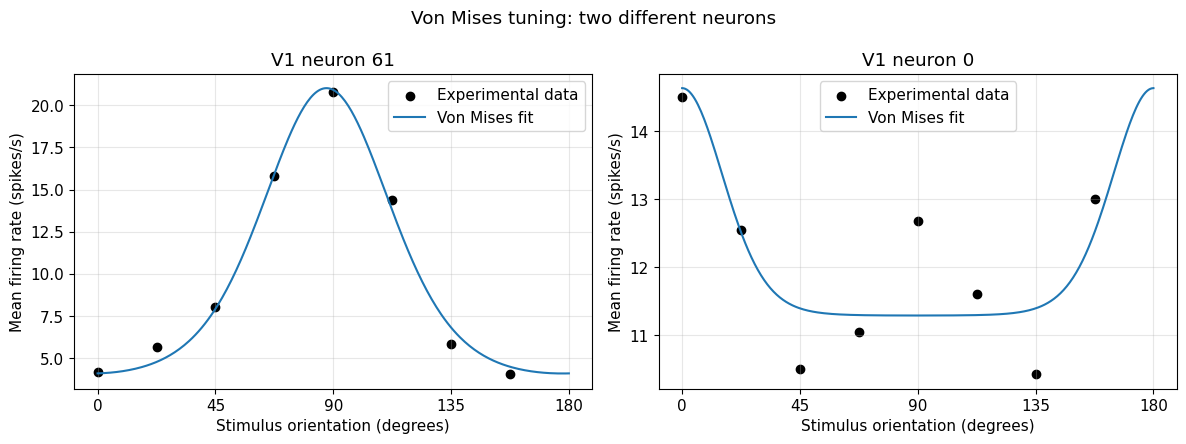

In [47]:
# Smooth angles for plotting
x_smooth = np.linspace(0, 180, 300)
x_smooth_rad = np.deg2rad(x_smooth)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Neuron 61
axes[0].scatter(angles_deg, mean_rates[61], color='black',
                label='Experimental data')
axes[0].plot(x_smooth, von_mises(x_smooth_rad, *params_vm),
             color='tab:blue', label='Von Mises fit')
axes[0].set_title('V1 neuron 61')

# Neuron 0
axes[1].scatter(angles_deg, mean_rates[0], color='black',
                label='Experimental data')
axes[1].plot(x_smooth, von_mises(x_smooth_rad, *params_vm0),
             color='tab:blue', label='Von Mises fit')
axes[1].set_title('V1 neuron 0')

for ax in axes:
    ax.set_xlabel('Stimulus orientation (degrees)')
    ax.set_ylabel('Mean firing rate (spikes/s)')
    ax.set_xticks(np.arange(0, 181, 45))
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle('Von Mises tuning: two different neurons')
plt.tight_layout()
plt.show()

## 6.1 Comparing different models

We also look for neurons with more variable trial responses. First, we calculate the standard deviation across trials for each orientation.


In [48]:
# Measure trial-to-trial variability for each neuron

noise_scores = []

for neuron in range(88):
    std_values = []

    for ori in orientations:
        trials = spike_counts[stim == ori, neuron]

        # How different are the responses across trials?
        std_values.append(np.std(trials))

    # Average variability across orientations
    noise_scores.append(np.mean(std_values))

noise_scores = np.array(noise_scores)

print('Neuron 61 noise score:', noise_scores[61])

# Show neurons with the highest variability
print('Highest variability:', np.argsort(noise_scores)[-10:][::-1])

Neuron 61 noise score: 5.404235553549061
Highest variability: [15 85 50 45 79 38 23 12 78 21]


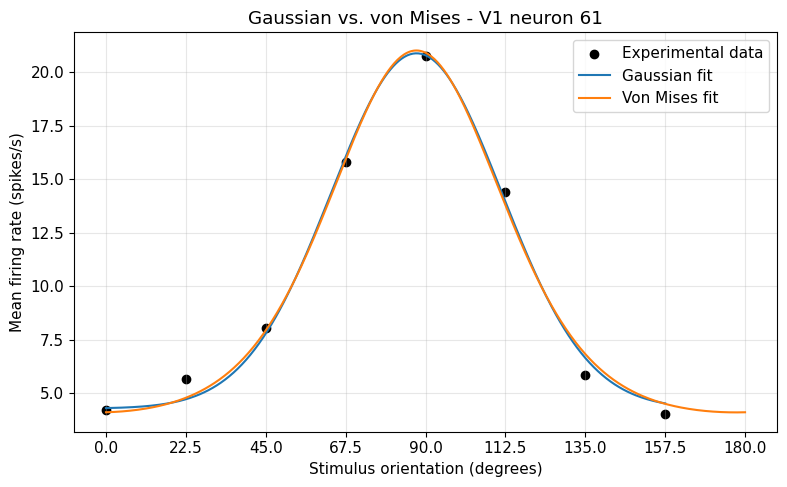

In [49]:
# Smooth x values for plotting
x_smooth_deg = np.linspace(0, 180, 400)
x_smooth_rad = np.deg2rad(x_smooth_deg)

# Gaussian prediction
# We use orientation codes 1..8 for the Gaussian model
x_codes_smooth = np.linspace(1, 8, 400)
y_gaussian_smooth = gaussian(x_codes_smooth, B, A, mu, sigma)

# Von Mises prediction
y_vm_smooth = von_mises(x_smooth_rad, B_vm, A_vm, mu_vm, kappa_vm)

plt.figure(figsize=(8, 5))

# Experimental data
plt.scatter(angles_deg, y, color='black', label='Experimental data')

# Gaussian fit
plt.plot(
    np.linspace(0, 157.5, 400),
    y_gaussian_smooth,
    color='tab:blue',
    label='Gaussian fit'
)

# Von Mises fit
plt.plot(
    x_smooth_deg,
    y_vm_smooth,
    color='tab:orange',
    label='Von Mises fit'
)

plt.xlabel('Stimulus orientation (degrees)')
plt.ylabel('Mean firing rate (spikes/s)')
plt.title('Gaussian vs. von Mises - V1 neuron 61')
plt.xticks(np.arange(0, 181, 22.5))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

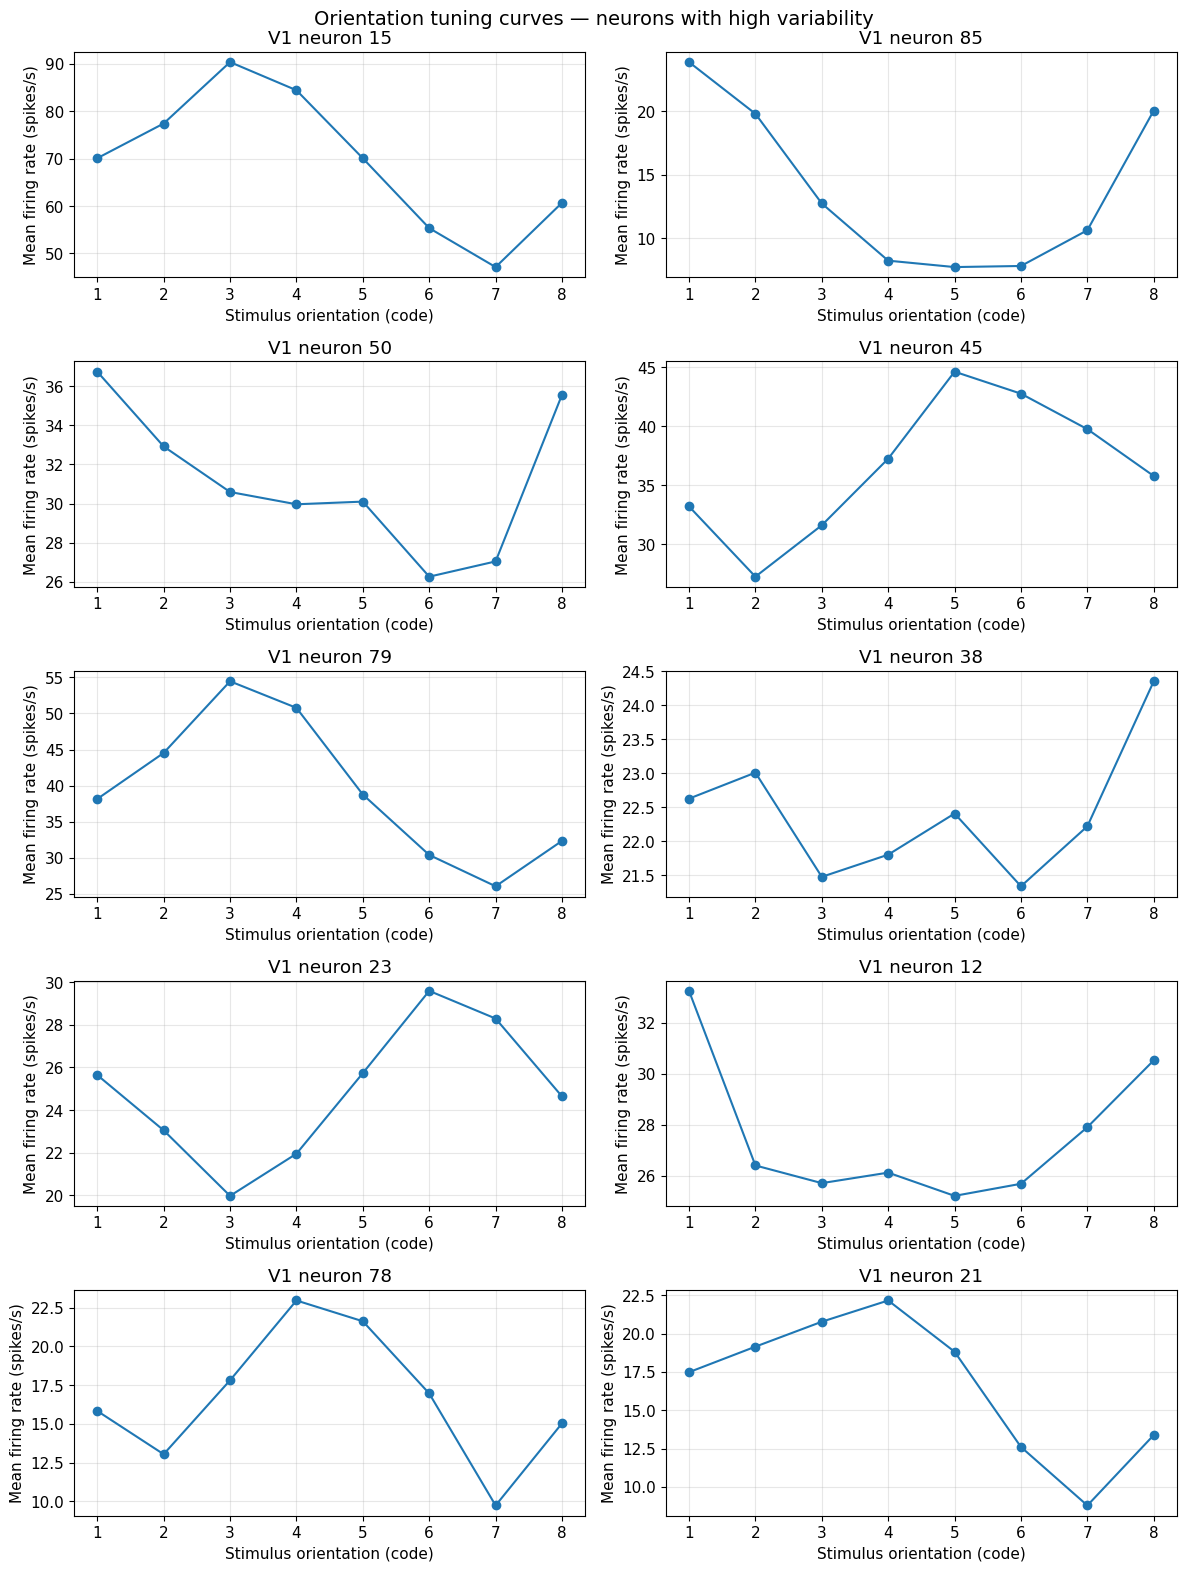

In [50]:
# Neurons with the highest trial-to-trial variability
noisy_neurons = [15, 85, 50, 45, 79, 38, 23, 12, 78, 21]

fig, axes = plt.subplots(5, 2, figsize=(12, 16))
axes = axes.flatten()

for i, neuron in enumerate(noisy_neurons):

    # Mean firing rate for this neuron
    y = mean_rates[neuron]

    # Plot the tuning curve
    axes[i].plot(orientations, y, marker='o', color='tab:blue')

    axes[i].set_title(f'V1 neuron {neuron}')
    axes[i].set_xlabel('Stimulus orientation (code)')
    axes[i].set_ylabel('Mean firing rate (spikes/s)')
    axes[i].set_xticks(orientations)
    axes[i].grid(alpha=0.3)

plt.suptitle('Orientation tuning curves — neurons with high variability',
             fontsize=14)
plt.tight_layout()
plt.show()

In [51]:
# Use neurons 12 and 50
extra_neurons = [12, 50]

# Orientation codes and real angles
x_code = orientations
x_deg = (orientations - 1) * 22.5
x_rad = np.deg2rad(x_deg)


In [52]:
# Save MSE and fit parameters
results_extra = {}

for neuron in extra_neurons:

    # Mean firing rates for this neuron
    y = mean_rates[neuron]

    # Fit degree 4 polynomial
    poly_coef = np.polyfit(x_code, y, 4)
    poly_model = np.poly1d(poly_coef)
    y_poly = poly_model(x_code)
    mse_poly = np.mean((y - y_poly) ** 2)

    # Fit Gaussian
    B0 = np.min(y)
    A0 = np.max(y) - B0
    mu0 = x_code[np.argmax(y)]
    sigma0 = 1.0

    params_g, cov_g = curve_fit(
        gaussian,
        x_code,
        y,
        p0=[B0, A0, mu0, sigma0],
        bounds=([0, 0, 1, 0.01], [np.inf, np.inf, 8, np.inf]),
        maxfev=10000
    )

    B_g, A_g, mu_g, sigma_g = params_g
    y_gauss = gaussian(x_code, B_g, A_g, mu_g, sigma_g)
    mse_gauss = np.mean((y - y_gauss) ** 2)

    # Fit von Mises
    B0_vm = np.min(y)
    kappa0 = 1.0
    mu0_vm = x_rad[np.argmax(y)]
    A0_vm = (np.max(y) - B0_vm) / np.exp(kappa0)

    params_vm, cov_vm = curve_fit(
        von_mises,
        x_rad,
        y,
        p0=[B0_vm, A0_vm, mu0_vm, kappa0],
        bounds=([0, 0, 0, 0], [np.inf, np.inf, np.pi, 20]),
        maxfev=10000
    )

    B_vm, A_vm, mu_vm, kappa_vm = params_vm
    y_vm = von_mises(x_rad, B_vm, A_vm, mu_vm, kappa_vm)
    mse_vm = np.mean((y - y_vm) ** 2)

    # Save everything
    results_extra[neuron] = {
        'y': y,
        'poly_coef': poly_coef,
        'mse_poly': mse_poly,
        'gaussian_params': params_g,
        'mse_gaussian': mse_gauss,
        'von_mises_params': params_vm,
        'mse_von_mises': mse_vm
    }

    # Print results
    print(f'Neuron {neuron}')
    print(f'4th-order polynomial MSE: {mse_poly:.4f}')
    print(f'Gaussian MSE: {mse_gauss:.4f}')
    print(f'Von Mises MSE: {mse_vm:.4f}')
    print('---')

Neuron 12
4th-order polynomial MSE: 0.2762
Gaussian MSE: 2.5874
Von Mises MSE: 1.5491
---
Neuron 50
4th-order polynomial MSE: 0.4130
Gaussian MSE: 6.7208
Von Mises MSE: 2.8362
---


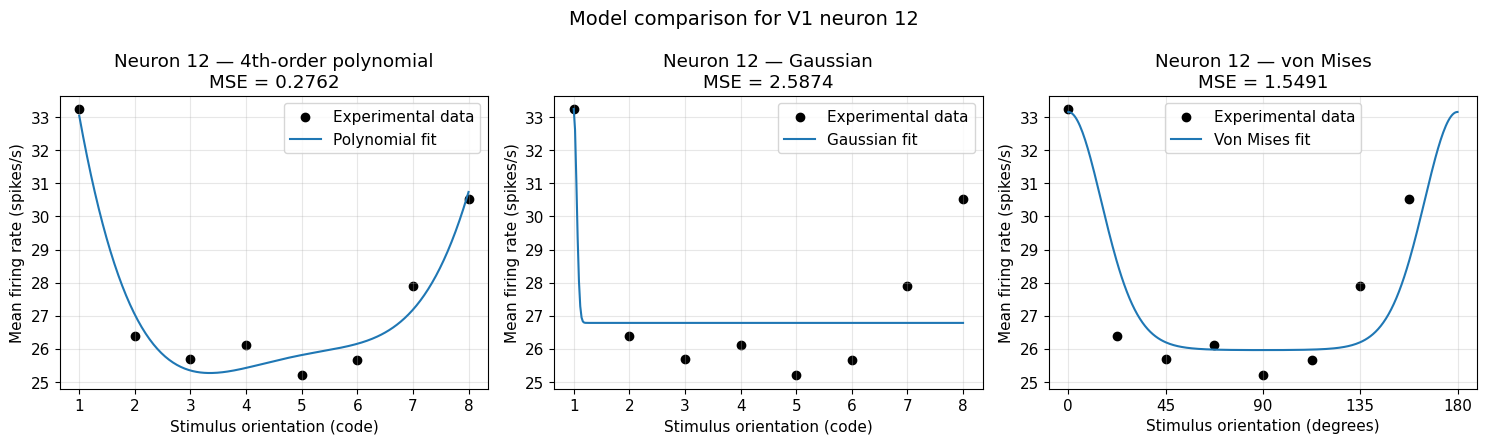

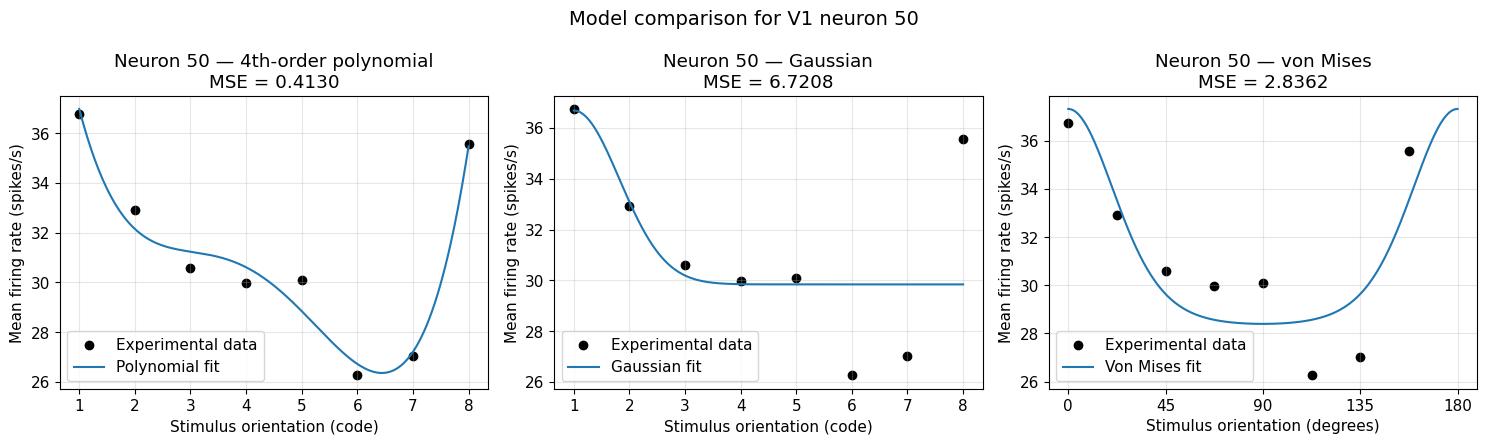

In [53]:
# Make smooth lines for the plots
x_code_smooth = np.linspace(1, 8, 300)
x_deg_smooth = np.linspace(0, 180, 300)
x_rad_smooth = np.deg2rad(x_deg_smooth)

for neuron in extra_neurons:

    y = results_extra[neuron]['y']

    poly_model = np.poly1d(results_extra[neuron]['poly_coef'])

    B_g, A_g, mu_g, sigma_g = results_extra[neuron]['gaussian_params']
    B_vm, A_vm, mu_vm, kappa_vm = results_extra[neuron]['von_mises_params']

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    # 1) Polynomial
    axes[0].scatter(x_code, y, color='black', label='Experimental data')
    axes[0].plot(x_code_smooth, poly_model(x_code_smooth),
                 color='tab:blue', label='Polynomial fit')
    axes[0].set_title(
        f'Neuron {neuron} — 4th-order polynomial\n'
        f'MSE = {results_extra[neuron]["mse_poly"]:.4f}'
    )
    axes[0].set_xlabel('Stimulus orientation (code)')
    axes[0].set_ylabel('Mean firing rate (spikes/s)')
    axes[0].set_xticks(x_code)
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    # 2) Gaussian
    axes[1].scatter(x_code, y, color='black', label='Experimental data')
    axes[1].plot(x_code_smooth,
                 gaussian(x_code_smooth, B_g, A_g, mu_g, sigma_g),
                 color='tab:blue', label='Gaussian fit')
    axes[1].set_title(
        f'Neuron {neuron} — Gaussian\n'
        f'MSE = {results_extra[neuron]["mse_gaussian"]:.4f}'
    )
    axes[1].set_xlabel('Stimulus orientation (code)')
    axes[1].set_ylabel('Mean firing rate (spikes/s)')
    axes[1].set_xticks(x_code)
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    # 3) von Mises
    axes[2].scatter(x_deg, y, color='black', label='Experimental data')
    axes[2].plot(x_deg_smooth,
                 von_mises(x_rad_smooth, B_vm, A_vm, mu_vm, kappa_vm),
                 color='tab:blue', label='Von Mises fit')
    axes[2].set_title(
        f'Neuron {neuron} — von Mises\n'
        f'MSE = {results_extra[neuron]["mse_von_mises"]:.4f}'
    )
    axes[2].set_xlabel('Stimulus orientation (degrees)')
    axes[2].set_ylabel('Mean firing rate (spikes/s)')
    axes[2].set_xticks(np.arange(0, 181, 45))
    axes[2].grid(alpha=0.3)
    axes[2].legend()

    plt.suptitle(f'Model comparison for V1 neuron {neuron}', fontsize=14)
    plt.tight_layout()
    plt.show()